<a href="https://colab.research.google.com/github/vikramsingh456/ai-ml/blob/dev/CohortOfSongs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== TASK 1: INITIAL INSPECTION ===
Initial Shape: (1610, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-n

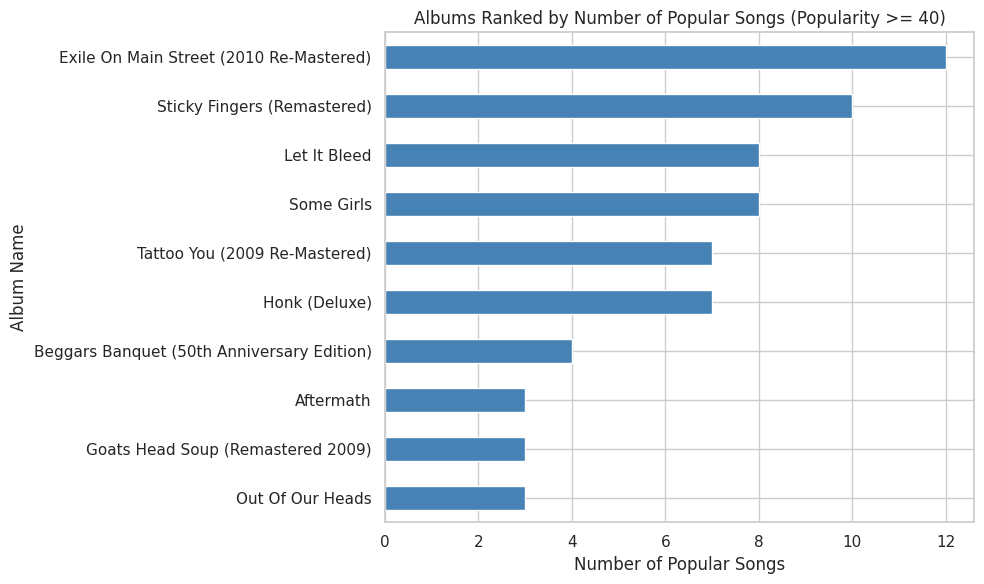


=== TASK 3B: FEATURE PATTERNS & EXPLORATION ===


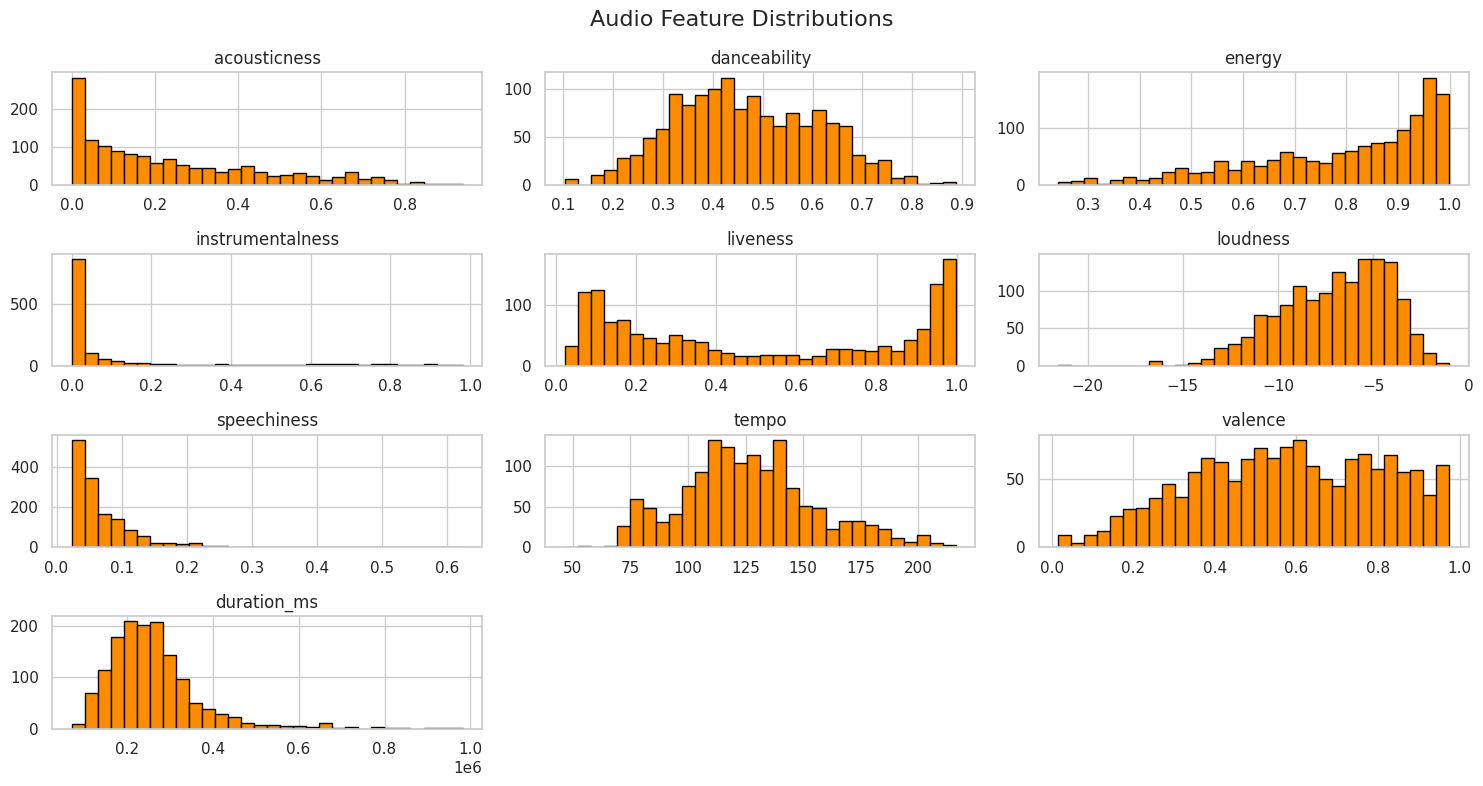

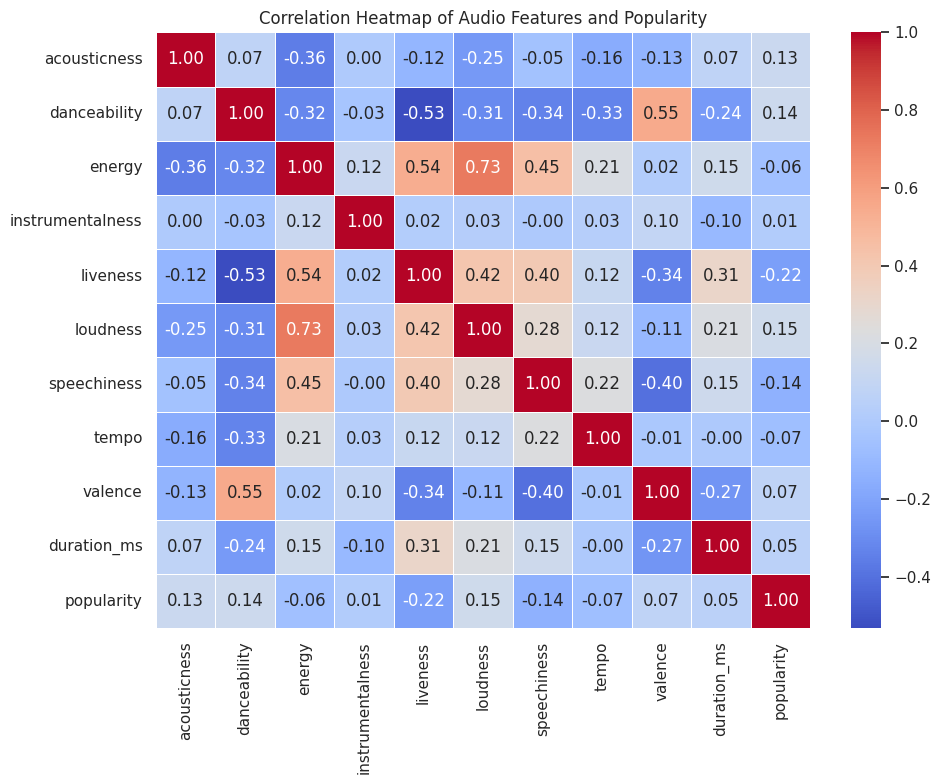


Live vs Studio Feature Means (0 = Studio, 1 = Live):
         acousticness  danceability    energy  instrumentalness  liveness  \
is_live                                                                     
0            0.253978       0.51027  0.735801          0.147765  0.293524   
1            0.207562       0.37887  0.907290          0.154332  0.935748   

         loudness  speechiness       tempo   valence    duration_ms  \
is_live                                                               
0       -7.705114     0.056914  124.155184  0.628863  238174.038382   
1       -5.676215     0.095877  130.736588  0.475296  306593.238806   

         popularity  
is_live              
0         23.303942  
1         17.761194  

=== TASK 3C: POPULARITY OVER TIME & ERAS ===
Correlation with Popularity:
liveness           -0.223757
speechiness        -0.140944
tempo              -0.067279
energy             -0.063502
instrumentalness    0.012257
duration_ms         0.054053
valence        

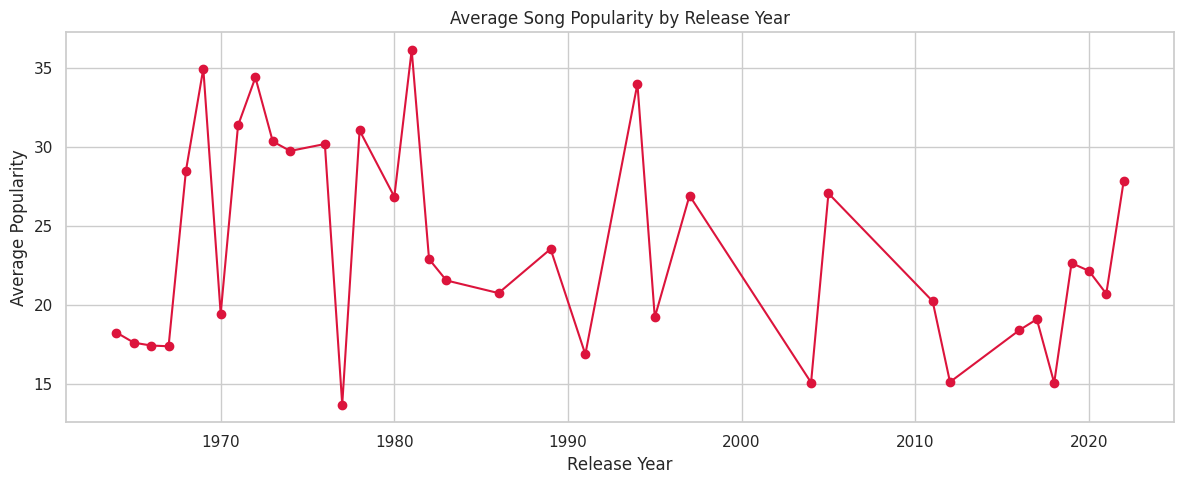


Feature-Popularity Correlations by Decade:
decade                1960      1970      1980      1990      2000      2010  \
acousticness      0.150354  0.258981 -0.030609 -0.115849 -0.095916  0.057256   
danceability      0.015859  0.226345  0.200819  0.044524  0.314479  0.277949   
energy           -0.066106 -0.056336 -0.029541 -0.134423 -0.161320 -0.140589   
instrumentalness -0.075815  0.063413 -0.182513 -0.087761 -0.066633  0.069771   
liveness         -0.127080 -0.476941 -0.091999 -0.262505 -0.406875 -0.359450   
loudness          0.007472  0.336484  0.248851  0.261789  0.217322  0.191321   
speechiness       0.015385 -0.224122 -0.160019  0.003514 -0.295191 -0.240627   
tempo            -0.024334 -0.091211 -0.167128 -0.029282 -0.185342 -0.087737   
valence          -0.044037  0.048949  0.075907 -0.191072  0.119825  0.184605   
duration_ms       0.199633 -0.008268  0.098123  0.001571 -0.032108 -0.052197   

decade                2020  
acousticness     -0.062969  
danceability     

/tmp/ipykernel_4477/2219838987.py:151: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  decadeCorrelations = df.groupby('decade').apply(lambda g: g[audioFeatures].corrwith(g['popularity'])).T


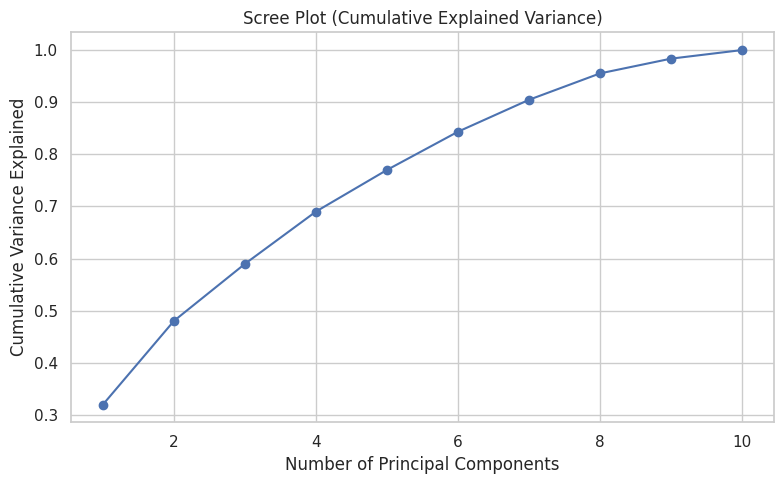

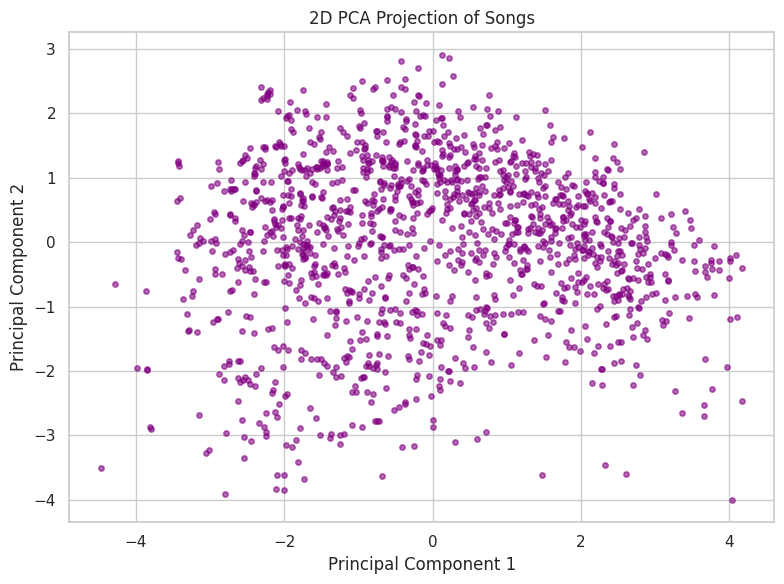

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Set display options and theme
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# ==========================================
# TASK 1 & TASK 2: INSPECT & REFINE DATA
# ==========================================
def inspectAndRefineData(filePath):
    # Load dataset[cite: 2]
    df = pd.read_csv(filePath)

    print("=== TASK 1: INITIAL INSPECTION ===")
    print(f"Initial Shape: {df.shape}")
    print(df.info())

    # Check missing values[cite: 2]
    missingVals = df.isnull().sum()
    print("\nMissing values:\n", missingVals[missingVals > 0] if missingVals.sum() > 0 else "No missing values.")

    # Check duplicates[cite: 2]
    exactDuplicates = df.duplicated().sum()
    idDuplicates = df['id'].duplicated().sum()
    print(f"Exact duplicate rows: {exactDuplicates}")
    print(f"Duplicate IDs: {idDuplicates}")

    audioFeaturesList = ['acousticness', 'danceability', 'energy', 'instrumentalness',
                         'liveness', 'loudness', 'speechiness', 'tempo', 'valence', 'duration_ms']

    audioDuplicates = df.duplicated(subset=['name'] + audioFeaturesList).sum()
    print(f"Same song with identical audio features: {audioDuplicates}")

    # TASK 2: Refine and Clean Data[cite: 2]
    cleaningLog = []
    initialRows = len(df)
    cleaningLog.append({'Step': 'Start', 'Rule': 'Raw data', 'RowsRemoved': 0, 'RowsLeft': initialRows})

    # Drop index column if present[cite: 2]
    if 'Unnamed: 0' in df.columns:
        df = df.drop(columns=['Unnamed: 0'])

    # Remove true duplicates keeping highest popularity[cite: 2]
    df = df.sort_values('popularity', ascending=False).drop_duplicates(subset=['name'] + audioFeaturesList, keep='first')
    rowsAfterDup = len(df)
    cleaningLog.append({'Step': 'Remove duplicates', 'Rule': 'Same name + identical audio features', 'RowsRemoved': initialRows - rowsAfterDup, 'RowsLeft': rowsAfterDup})

    # Remove irrelevant short tracks under 60 seconds[cite: 2]
    df = df[df['duration_ms'] >= 60000]
    rowsAfterShort = len(df)
    cleaningLog.append({'Step': 'Remove short tracks', 'Rule': 'duration < 60s', 'RowsRemoved': rowsAfterDup - rowsAfterShort, 'RowsLeft': rowsAfterShort})

    # Fix data types and create engineered features[cite: 2]
    df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
    df['release_year'] = df['release_date'].dt.year
    df['duration_min'] = df['duration_ms'] / 60000
    df['is_live'] = (df['liveness'] > 0.8).astype(int)
    df['decade'] = (df['release_year'] // 10) * 10

    print("\nCleaning Log:")
    print(pd.DataFrame(cleaningLog))
    print(f"Final Data Shape: {df.shape}")

    return df, audioFeaturesList

dfData, audio = inspectAndRefineData('/content/rolling_stones_spotify.csv')


# ==========================================
# TASK 3A: FIND TOP 2 ALBUMS
# ==========================================
def findTopAlbums(df):
    print("\n=== TASK 3A: TOP ALBUMS TO RECOMMEND ===")

    # Define popular songs threshold (popularity >= 40)[cite: 2]
    popularSongsDf = df[df['popularity'] >= 40]
    topAlbumsSeries = popularSongsDf['album'].value_counts().head(10)

    print("Top 10 albums by number of popular songs (popularity >= 40):")
    print(topAlbumsSeries)

    # Plot bar chart[cite: 2]
    plt.figure(figsize=(10, 6))
    topAlbumsSeries.sort_values().plot(kind='barh', color='steelblue')
    print("Albums Ranked by Number of Popular Songs (Popularity >= 40)")
    plt.title('Albums Ranked by Number of Popular Songs (Popularity >= 40)')
    plt.xlabel('Number of Popular Songs')
    plt.ylabel('Album Name')
    plt.tight_layout()
    plt.show()

findTopAlbums(dfData)


# ==========================================
# TASK 3B: EXPLORE SONG FEATURES
# ==========================================
def exploreSongFeatures(df, audioFeatures):
    print("\n=== TASK 3B: FEATURE PATTERNS & EXPLORATION ===")

    # Feature distributions[cite: 2]
    df[audioFeatures].hist(bins=30, figsize=(15, 8), color='darkorange', edgecolor='black')
    plt.suptitle('Audio Feature Distributions', fontsize=16)
    plt.tight_layout()
    plt.show()

    # Correlation heatmap[cite: 2]
    plt.figure(figsize=(10, 8))
    correlationMatrix = df[audioFeatures + ['popularity']].corr()
    sns.heatmap(correlationMatrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
    plt.title('Correlation Heatmap of Audio Features and Popularity')
    plt.tight_layout()
    plt.show()

    # Compare live vs studio songs[cite: 2]
    liveComparison = df.groupby('is_live')[audioFeatures + ['popularity']].mean()
    print("\nLive vs Studio Feature Means (0 = Studio, 1 = Live):")
    print(liveComparison)

exploreSongFeatures(dfData, audio)


# ==========================================
# TASK 3C: POPULARITY OVER TIME
# ==========================================
def analyzePopularityOverTime(df, audioFeatures):
    print("\n=== TASK 3C: POPULARITY OVER TIME & ERAS ===")

    # Correlation with popularity[cite: 2]
    popularityCorr = df[audioFeatures + ['popularity']].corr()['popularity'].sort_values()
    print("Correlation with Popularity:")
    print(popularityCorr)

    # Popularity trend by year[cite: 2]
    plt.figure(figsize=(12, 5))
    df.groupby('release_year')['popularity'].mean().plot(marker='o', color='crimson')
    plt.title('Average Song Popularity by Release Year')
    plt.xlabel('Release Year')
    plt.ylabel('Average Popularity')
    plt.tight_layout()
    plt.show()

    # Era comparison (correlations by decade)[cite: 2]
    decadeCorrelations = df.groupby('decade').apply(lambda g: g[audioFeatures].corrwith(g['popularity'])).T
    print("\nFeature-Popularity Correlations by Decade:")
    print(decadeCorrelations)

analyzePopularityOverTime(dfData, audio)


# ==========================================
# TASK 3D: DIMENSIONALITY REDUCTION (PCA)
# ==========================================
def performPcaAnalysis(df, audioFeatures):
    print("\n=== TASK 3D: DIMENSIONALITY REDUCTION (PCA) ===")

    # Standardize features[cite: 2]
    scaler = StandardScaler()
    scaledFeatures = scaler.fit_transform(df[audioFeatures])

    # Fit PCA[cite: 2]
    pcaObj = PCA()
    pcaObj.fit(scaledFeatures)

    explainedVarianceRatio = pcaObj.explained_variance_ratio_
    cumulativeVariance = np.cumsum(explainedVarianceRatio)

    print("Explained Variance Ratio per PC:", explainedVarianceRatio.round(3))
    print("Cumulative Explained Variance:", cumulativeVariance.round(3))

    # Scree Plot[cite: 2]
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(cumulativeVariance) + 1), cumulativeVariance, marker='o', linestyle='-', color='b')
    plt.title('Scree Plot (Cumulative Explained Variance)')
    plt.xlabel('Number of Principal Components')
    plt.ylabel('Cumulative Variance Explained')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 2D PCA Scatter Plot[cite: 2]
    pca2D = PCA(n_components=2)
    transformedData = pca2D.fit_transform(scaledFeatures)

    plt.figure(figsize=(8, 6))
    plt.scatter(transformedData[:, 0], transformedData[:, 1], alpha=0.6, c='purple', s=15)
    plt.title('2D PCA Projection of Songs')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.tight_layout()
    plt.show()

    return scaledFeatures

scaledDataMatrix = performPcaAnalysis(dfData, audio)


# ==========================================
# TASK 4: CLUSTER ANALYSIS & COHORTS
# ==========================================
def performClusterAnalysis(df, scaledMatrix, audioFeatures):
    print("\n=== TASK 4: CLUSTER ANALYSIS ===")

    # 4a. Elbow method and silhouette scores